# Lab 1 — Intro to Behavioral TV Data
Name: *Vladislav* | Group: *KM_43*

## Setup

In [1]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")  # Colab and Kaggle
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"])
programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"])

In [2]:
# Quick look at the data
for name, df in [("programs", programs), ("viewings", viewings), ("daily_weights", daily_weights),
                 ("viewer_attributes", viewer_attributes), ("attributes", attributes)]:
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} columns")
print("Viewings from", viewings["start_ts"].min(), "to", viewings["end_ts"].max())
print("Broadcast dates from", daily_weights["broadcast_date"].min().date(), "to", daily_weights["broadcast_date"].max().date())
print("Sessions by respondent type:", viewings["resp_type"].value_counts().to_dict())

programs: 5841 rows x 15 columns
viewings: 1001885 rows x 9 columns
daily_weights: 407561 rows x 4 columns
viewer_attributes: 104679 rows x 3 columns
attributes: 58 rows x 5 columns
Viewings from 2024-10-01 06:00:00 to 2024-11-01 06:00:00
Broadcast dates from 2024-10-01 to 2024-10-31
Sessions by respondent type: {'R': 517973, 'H': 466630, 'S': 11996, 'L': 5286}


### Decoding attribute codes
`viewer_attributes` stores characteristics as codes (one row per respondent and code). Joining it with `attributes` on `attr_id` gives every code its name; from that we build one row per person with sex (codes 201/202) and age in years (code 300, column `value`).

In [3]:
va = viewer_attributes.merge(attributes, on="attr_id", how="left")
sex = (va[va["attr_id"].isin([201, 202])]
        [["respondent_id", "attr_name"]]
        .rename(columns={"attr_name": "sex"}))
age = (va[va["attr_id"] == 300]
        [["respondent_id", "value"]]
        .rename(columns={"value": "age"}))
persons = sex.merge(age, on="respondent_id")

display(va.head(8))
display(persons.head())
print("Persons with sex and age:", len(persons))

,respondent_id,attr_id,value,attr_group,attr_name,value_type,applies_to
0,10000100,104,NaN,Respondent type,H: household record (id ending 00),flag,"H,R,L,S"
1,10000100,802,NaN,Household size,2 persons,flag,H
2,10000100,815,NaN,Household income,$100k-$150k,flag,H
3,10000100,822,NaN,Children in household,No children under 18,flag,H
4,10000100,833,NaN,TV reception,Telco / fiber,flag,H
5,10000100,843,NaN,Census region,South,flag,H
6,10000100,852,NaN,County size,B: large,flag,H
7,10000101,101,NaN,Respondent type,R: panel member (household member),flag,"H,R,L,S"


,respondent_id,sex,age
0,10000101,Female,48.0
1,10000102,Male,47.0
2,10000201,Male,32.0
3,10000202,Male,2.0
4,10000301,Female,48.0


Persons with sex and age: 10216


### Helpers
- **Persons** = R and L rows only (S guests are excluded everywhere); household numbers use the H rows.
- **Watched a telecast** = at least 1 minute of the respondent's sessions on that network overlap `[start_ts, end_ts)` of the telecast (overlaps of all sessions are summed).
- **Monthly weight** = a person's average daily weight over the days he/she was in-tab; used for reach and frequency.

In [4]:
def weighted_quantile(values, weights, q):
    """First value whose cumulative weight share is >= q."""
    order = np.argsort(np.asarray(values), kind="stable")
    v = np.asarray(values)[order]
    w = np.asarray(weights, dtype=float)[order]
    cum = np.cumsum(w) / w.sum()
    return v[np.searchsorted(cum, q)]


def telecast_viewers(sessions, telecasts):
    """(telecast_id, respondent_id, minutes) for everyone who watched >= 1 minute of a telecast."""
    m = sessions.merge(telecasts[["telecast_id", "network_code", "start_ts", "end_ts"]],
                       on="network_code", suffixes=("", "_tc"))
    m = m[(m["start_ts"] < m["end_ts_tc"]) & (m["end_ts"] > m["start_ts_tc"])]
    m["minutes"] = (m["end_ts"].clip(upper=m["end_ts_tc"])
                    - m["start_ts"].clip(lower=m["start_ts_tc"])).dt.total_seconds() / 60
    out = m.groupby(["telecast_id", "respondent_id"], as_index=False)["minutes"].sum()
    return out[out["minutes"] >= 1]


pv = viewings[viewings["resp_type"].isin(["R", "L"])].reset_index(drop=True)
hv = viewings[viewings["resp_type"] == "H"].reset_index(drop=True)

# monthly weight for every person in-tab at least one day in October, with sex and age
monthly = (daily_weights[daily_weights["resp_type"].isin(["R", "L"])]
           .groupby("respondent_id")["weight"].mean().rename("mw").reset_index()
           .merge(persons, on="respondent_id", how="left"))
print("Persons with a monthly weight:", len(monthly))

Persons with a monthly weight: 10210


## Task 1.1 — Panel and universe

In [5]:
n_telecasts = programs["telecast_id"].nunique()
n_programs = programs["program_name"].nunique()
n_networks = programs["network_code"].nunique()

# panel = everyone in-tab at least one day in October (households = H, persons = R + L)
dw_h = daily_weights[daily_weights["resp_type"] == "H"]
dw_p = daily_weights[daily_weights["resp_type"].isin(["R", "L"])]

# every broadcast day: how many are in-tab and how many US households / persons their weights add up to
daily = pd.DataFrame({
    "Households in-tab": dw_h.groupby("broadcast_date")["respondent_id"].nunique(),
    "Persons in-tab": dw_p.groupby("broadcast_date")["respondent_id"].nunique(),
    "US TV households (M)": dw_h.groupby("broadcast_date")["weight"].sum() / 1e6,
    "US persons (M)": dw_p.groupby("broadcast_date")["weight"].sum() / 1e6,
})
display(daily.round(2).head())

print("Telecasts:", n_telecasts)
print("Programs:", n_programs)
print("Networks:", n_networks)
print("Households in panel:", dw_h["respondent_id"].nunique())
print("Persons in panel:", dw_p["respondent_id"].nunique())
print("Households in-tab, average day:", f"{daily['Households in-tab'].mean():.1f}")
print("Persons in-tab, average day:", f"{daily['Persons in-tab'].mean():.1f}")
print("US TV households represented, average day (M):", f"{daily['US TV households (M)'].mean():.2f}")
print("US persons represented, average day (M):", f"{daily['US persons (M)'].mean():.2f}")

,Households in-tab,Persons in-tab,US TV households (M),US persons (M)
broadcast_date,,,,
2024-10-01,3884,9269,125.8,317.28
2024-10-02,3881,9241,125.8,317.28
2024-10-03,3864,9203,125.8,317.28
2024-10-04,3857,9190,125.8,317.28
2024-10-05,3858,9190,125.8,317.28


Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.5
Persons in-tab, average day: 9268.7
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 317.28


In [6]:
# viewer_attributes lists the whole panel roster: code 104 = household record, 101 / 102 = persons (R / L)
va_h_count = viewer_attributes[viewer_attributes["attr_id"] == 104]["respondent_id"].nunique()
va_p_count = viewer_attributes[viewer_attributes["attr_id"].isin([101, 102])]["respondent_id"].nunique()
print("Households in viewer_attributes:", va_h_count)
print("Persons in viewer_attributes:", va_p_count)
print("Never in-tab in October (households / persons):",
      va_h_count - dw_h["respondent_id"].nunique(), "/", va_p_count - dw_p["respondent_id"].nunique())

Households in viewer_attributes: 4256
Persons in viewer_attributes: 10216
Never in-tab in October (households / persons): 2 / 6


**Answer:**
- The schedule has **5841 telecasts** of **246 distinct programs** on **10 networks** (*Local / Syndicated Programming* is counted as one program).
- **4254 households** and **10210 persons** (R + L) were in-tab at least once in October (`daily_weights`).
- `viewer_attributes` lists a few more: **4256 households** (code 104) and **10216 persons** (codes 101/102). It describes the whole panel roster, while `daily_weights` only has respondents who were in-tab on at least one October day. The extra 2 households / 6 persons belong to the panel but never produced a valid in-tab day this month (e.g. they joined or left at the month boundary, or their meter did not report), so they have no daily weight.
- On an average day about **3878 households** and **9269 persons** are in-tab. Their weights add up to **125.80 M** US TV households and **317.28 M** persons, i.e. exactly the universe (125.8 M TV households, 317.3 M persons 2+).

## Task 1.2 — Average audience by hour of day

In [7]:
# split every person session at hour boundaries: one row per (session, clock hour)
ph = pv.copy()
ph["h0"] = ph["start_ts"].dt.floor("h")
ph["h1"] = (ph["end_ts"] - pd.Timedelta(minutes=1)).dt.floor("h")
ph["n_hours"] = ((ph["h1"] - ph["h0"]) / pd.Timedelta(hours=1)).astype(int) + 1
ph = ph.loc[ph.index.repeat(ph["n_hours"])].copy()
ph["k"] = ph.groupby(level=0).cumcount()
ph["hour_ts"] = ph["h0"] + pd.to_timedelta(ph["k"], unit="h")

ph["minutes"] = (ph["end_ts"].clip(upper=ph["hour_ts"] + pd.Timedelta(hours=1))
                 - ph["start_ts"].clip(lower=ph["hour_ts"])).dt.total_seconds() / 60
ph["wmin"] = ph["minutes"] * ph["weight"]

# broadcast day (06:00-05:59), weekday / weekend by broadcast day, clock hour
ph["bdate"] = (ph["hour_ts"] - pd.Timedelta(hours=6)).dt.normalize()
ph = ph[(ph["bdate"] >= "2024-10-01") & (ph["bdate"] <= "2024-10-31")]
ph["day_type"] = np.where(ph["bdate"].dt.dayofweek >= 5, "weekend", "weekday")
ph["hour"] = ph["hour_ts"].dt.hour

n_days = ph.groupby("day_type")["bdate"].nunique()
print("Broadcast days:", n_days.to_dict())

# average audience (M persons) = weighted minutes / 60 / number of days
aud = ph.groupby(["day_type", "hour"])["wmin"].sum() / 60
aud = aud.unstack("day_type") / n_days / 1e6
display(aud.round(2).T)

Broadcast days: {'weekday': 23, 'weekend': 8}


hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,
weekday,11.39,6.30,3.08,1.87,1.09,0.89,2.26,6.99,9.55,8.93,...,9.03,9.76,8.92,11.97,13.84,19.32,34.17,35.08,29.91,16.52
weekend,12.69,6.89,3.83,2.27,1.38,1.00,2.25,6.86,9.37,11.93,...,18.51,19.16,20.03,20.65,21.66,27.16,37.49,37.02,33.31,19.99


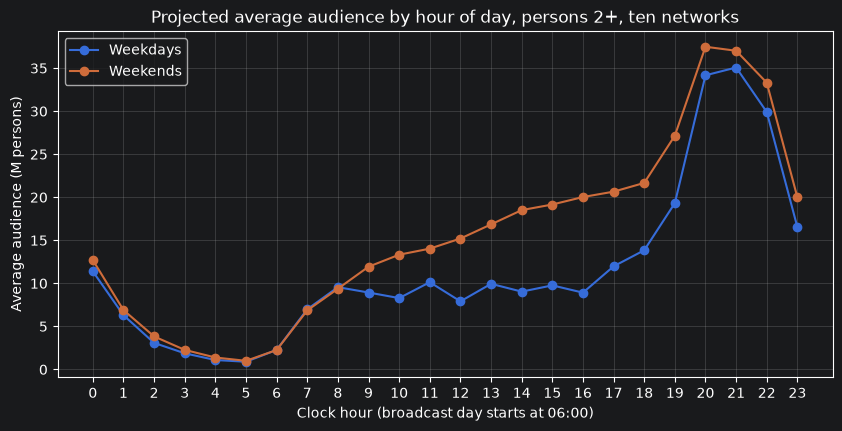

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [8]:
# plot: projected average audience (M) by clock hour, weekday vs weekend
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(aud.index, aud["weekday"], marker="o", label="Weekdays")
ax.plot(aud.index, aud["weekend"], marker="o", label="Weekends")
ax.set_xticks(range(24))
ax.set_xlabel("Clock hour (broadcast day starts at 06:00)")
ax.set_ylabel("Average audience (M persons)")
ax.set_title("Projected average audience by hour of day, persons 2+, ten networks")
ax.grid(alpha=0.3)
ax.legend()
plt.show()
print("Peak hour, weekdays:", int(aud["weekday"].idxmax()))
print("Peak hour, weekends:", int(aud["weekend"].idxmax()))

**Answer:** Both days peak in prime time: weekdays at **21:00 (≈35.1 M persons per minute)**, weekends one hour earlier at **20:00 (≈37.5 M)**. The big difference is the daytime: on weekdays the audience stays low between 9:00 and 17:00 (about 8-12 M, people are at work/school) and only takes off after 18:00, while on weekends it climbs steadily from the morning (≈13 M at 10:00, ≈18.5 M at 14:00 vs ≈9 M on weekdays, ≈21 M at 17-18), roughly twice the weekday level. So the weekend curve is flatter and higher across the day, prime time starts earlier, and late night (23:00-02:00) is also a bit higher. Early morning (6-8) looks the same on both.

## Task 1.3 — Session length

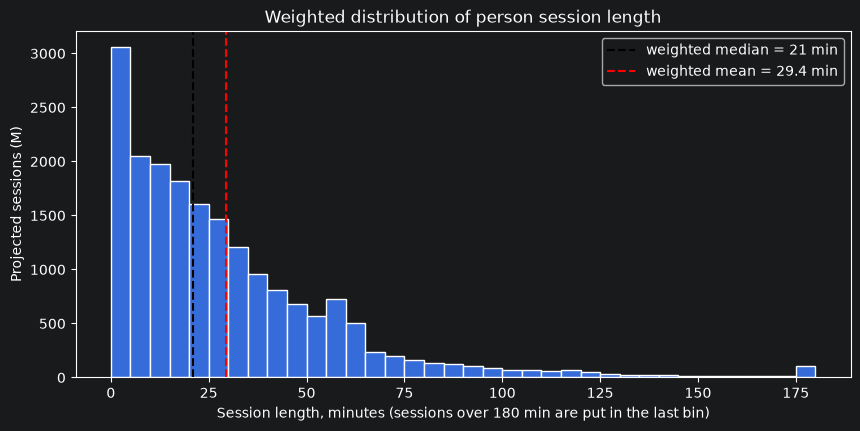

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [9]:
length = (pv["end_ts"] - pv["start_ts"]).dt.total_seconds() / 60
w = pv["weight"]
mean_len = np.average(length, weights=w)
median_len = weighted_quantile(length, w, 0.5)
p99 = weighted_quantile(length, w, 0.99)

# plot: weighted distribution of person session length
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(length.clip(upper=180), bins=np.arange(0, 185, 5), weights=w / 1e6, edgecolor="white")
ax.axvline(median_len, color="black", linestyle="--", label=f"weighted median = {median_len:.0f} min")
ax.axvline(mean_len, color="red", linestyle="--", label=f"weighted mean = {mean_len:.1f} min")
ax.set_xlabel("Session length, minutes (sessions over 180 min are put in the last bin)")
ax.set_ylabel("Projected sessions (M)")
ax.set_title("Weighted distribution of person session length")
ax.legend()
plt.show()
print("Session length, weighted mean (min):", f"{mean_len:.1f}")
print("Session length, weighted median (min):", f"{median_len:.1f}")

In [10]:
print("Weighted 99th percentile (min):", f"{p99:.1f}")
print("Longest session (min):", f"{length.max():.1f}")
print("Share of sessions of 5 minutes or less (weighted):", f"{w[length <= 5].sum() / w.sum():.3f}")

Weighted 99th percentile (min): 145.0
Longest session (min): 388.0
Share of sessions of 5 minutes or less (weighted): 0.182


**Answer:** The distribution is strongly right-skewed: lots of short sessions (≈18 % of weighted sessions last 5 minutes or less: channel surfing, checking the news), most sessions under an hour, and a long tail of very long sessions (99th percentile ≈145 min, the longest ≈6.5 hours). The tail pulls the **mean (29.4 min)** above the **median (21 min)**. For a client deck I would show the **median** ("a typical viewing session lasts about 20 minutes") because it is not driven by a few marathon sessions; the mean can be added as context (it is what you multiply by the number of sessions to get total time).

## Task 2 — Program reach curve

In [11]:
cen = programs[(programs["network_code"] == "CBS") & (programs["program_name"] == "CBS Evening News")]
cen = cen[cen["broadcast_date"].dt.dayofweek < 5].sort_values("start_ts")

# daily weights of households (dw_h) and persons (dw_p) come from Task 1.1
keys = ["respondent_id", "broadcast_date", "weight"]

# viewers (>= 1 minute) with their weight on the telecast's broadcast date
v_hh = (telecast_viewers(hv, cen).merge(cen[["telecast_id", "broadcast_date"]], on="telecast_id")
        .merge(dw_h[keys], on=["respondent_id", "broadcast_date"]))
v_pp = (telecast_viewers(pv, cen).merge(cen[["telecast_id", "broadcast_date"]], on="telecast_id")
        .merge(dw_p[keys], on=["respondent_id", "broadcast_date"]))

# denominators: everyone in-tab on that broadcast date
intab_hh = dw_h.groupby("broadcast_date")["weight"].sum()
intab_pp = dw_p.groupby("broadcast_date")["weight"].sum()

# table: household rating, P2+ rating, projected audience (M) per telecast
ratings = cen[["telecast_id", "broadcast_date"]].set_index("telecast_id")
ratings["HH rating (%)"] = v_hh.groupby("telecast_id")["weight"].sum() / ratings["broadcast_date"].map(intab_hh) * 100
ratings["P2+ rating (%)"] = v_pp.groupby("telecast_id")["weight"].sum() / ratings["broadcast_date"].map(intab_pp) * 100
ratings["Projected audience (M)"] = v_pp.groupby("telecast_id")["weight"].sum() / 1e6
ratings["broadcast_date"] = ratings["broadcast_date"].dt.date
display(ratings.round(2))

# cumulative reach: telecast number at which each person watched for the first time
air_order = pd.Series(range(1, len(cen) + 1), index=cen["telecast_id"])
first_seen = v_pp.assign(k=v_pp["telecast_id"].map(air_order)).groupby("respondent_id")["k"].min()
reach_base = monthly.set_index("respondent_id").join(first_seen)

groups = {"P2+": reach_base["age"] >= 2,
          "A18-34": reach_base["age"].between(18, 34),
          "A18-49": reach_base["age"].between(18, 49)}
reach = pd.DataFrame(index=air_order.values)
for g, mask in groups.items():
    base = reach_base[mask]
    reach[g] = [base.loc[base["k"] <= k, "mw"].sum() / base["mw"].sum() * 100 for k in reach.index]
reach.index.name = "telecast #"
display(reach.round(1).T)

,broadcast_date,HH rating (%),P2+ rating (%),Projected audience (M)
telecast_id,,,,
1003837,2024-10-01,3.47,1.67,5.28
1003857,2024-10-02,3.07,1.48,4.68
1003877,2024-10-03,2.99,1.47,4.68
1003896,2024-10-04,3.00,1.51,4.81
1003936,2024-10-07,3.06,1.52,4.83
1003952,2024-10-08,3.17,1.57,4.97
1003970,2024-10-09,2.98,1.48,4.70
1003985,2024-10-10,3.38,1.62,5.13
1004001,2024-10-11,3.09,1.48,4.69


telecast #,1,2,3,4,5,6,7,8,9,10,...,14,15,16,17,18,19,20,21,22,23
P2+,1.5,2.4,2.9,3.3,3.8,4.3,4.7,5.2,5.5,5.8,...,7.1,7.3,7.6,8.1,8.3,8.7,9.1,9.3,9.5,9.9
A18-34,0.1,0.2,0.3,0.4,0.7,0.9,0.9,1.0,1.1,1.2,...,1.4,1.4,1.6,1.9,1.9,2.0,2.2,2.4,2.4,2.6
A18-49,0.4,0.6,0.8,1.0,1.1,1.3,1.4,1.7,1.9,2.1,...,2.7,2.8,3.0,3.3,3.4,3.5,3.8,4.0,4.1,4.4


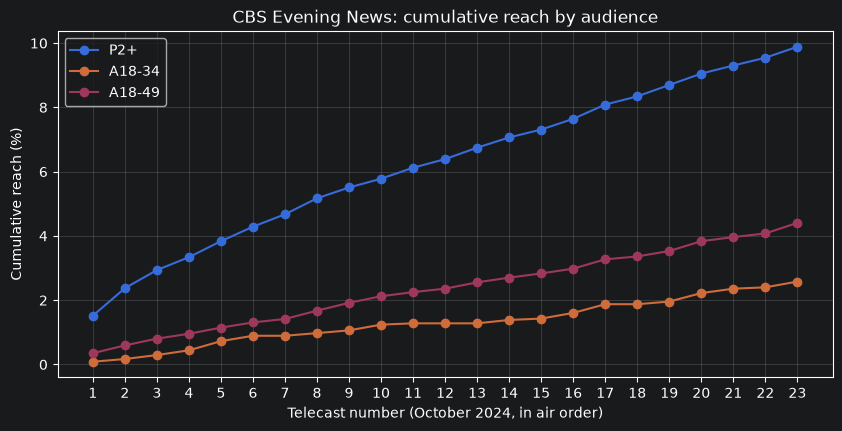

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [12]:
# plot: cumulative reach P2+, A18-34, A18-49
fig, ax = plt.subplots(figsize=(10, 4.5))
for g in reach.columns:
    ax.plot(reach.index, reach[g], marker="o", label=g)
ax.set_xticks(reach.index)
ax.set_xlabel("Telecast number (October 2024, in air order)")
ax.set_ylabel("Cumulative reach (%)")
ax.set_title("CBS Evening News: cumulative reach by audience")
ax.grid(alpha=0.3)
ax.legend()
plt.show()
print("Telecasts of the program:", len(cen))
print("Average household rating (%):", f"{ratings['HH rating (%)'].mean():.1f}")
print("Average P2+ rating (%):", f"{ratings['P2+ rating (%)'].mean():.1f}")
print("Average projected audience (M):", f"{ratings['Projected audience (M)'].mean():.2f}")
print("Final reach P2+ (%):", f"{reach['P2+'].iloc[-1]:.1f}")
print("Final reach A18-34 (%):", f"{reach['A18-34'].iloc[-1]:.1f}")
print("Final reach A18-49 (%):", f"{reach['A18-49'].iloc[-1]:.1f}")

**Answer:** The rating of each telecast is almost flat (P2+ between 1.3 % and 1.8 %, ≈4.9 M viewers a night), but every evening the audience is only *partly* the same people: some regulars watch most nights, others drop in once or twice. Each new telecast therefore adds people who have not watched before, so cumulative reach keeps growing. The biggest jump comes with the second telecast, after that each night still adds about 0.3-0.5 points of new viewers, and the curve has not flattened out by the end of the month: from 1.5 % after the first telecast to **9.9 % of persons 2+ after 23 telecasts**, about 6× the single-night rating. The program reaches the **oldest audience best**: final reach is 9.9 % for P2+, but only 4.4 % for A18-49 and 2.6 % for A18-34, so the viewers are mostly 50+. That matches what is known about network evening news: a habit of older viewers, while younger adults get news online and on demand.

## Task 3 — Program frequency

In [13]:
yr = programs[(programs["network_code"] == "CBS") & (programs["program_name"] == "The Young and the Restless")]
v_yr = telecast_viewers(pv, yr)

# frequency = number of different telecasts watched; each viewer gets his/her monthly weight
freq = (v_yr.groupby("respondent_id")["telecast_id"].nunique().rename("freq").reset_index()
        .merge(monthly[["respondent_id", "mw"]], on="respondent_id", how="left"))
print("Telecasts:", len(yr), "| panel viewers:", len(freq))

dist = freq.groupby("freq")["mw"].sum() / 1e6
display(dist.round(2).to_frame("Projected viewers (M)").T)

# most loyal viewers: frequency at or above the weighted 80th percentile (whole frequency levels)
p80 = weighted_quantile(freq["freq"], freq["mw"], 0.8)
loyal = freq["freq"] >= p80
views = freq["freq"] * freq["mw"]

Telecasts: 23 | panel viewers: 799


freq,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Projected viewers (M),15.85,5.22,2.25,1.54,0.79,0.44,0.4,0.38,0.17,0.12,0.3,0.25,0.17,0.3,0.57,0.41,0.58,0.55,0.26,0.25


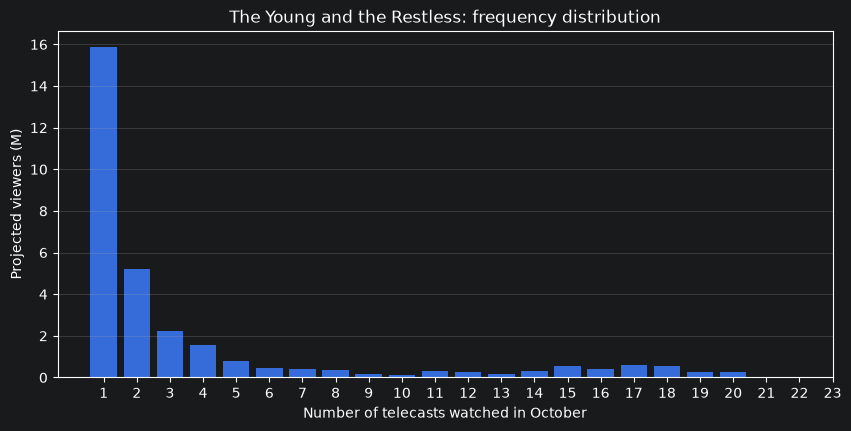

Projected viewers (M): 30.80
Average frequency (weighted): 3.63
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704


In [14]:
# plot: projected viewers (M) by number of telecasts watched
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(dist.index, dist.values)
ax.set_xticks(range(1, len(yr) + 1))
ax.set_xlabel("Number of telecasts watched in October")
ax.set_ylabel("Projected viewers (M)")
ax.set_title("The Young and the Restless: frequency distribution")
ax.grid(alpha=0.3, axis="y")
plt.show()
print("Projected viewers (M):", f"{freq['mw'].sum() / 1e6:.2f}")
print("Average frequency (weighted):", f"{np.average(freq['freq'], weights=freq['mw']):.2f}")
print("Median frequency (weighted):", weighted_quantile(freq["freq"], freq["mw"], 0.5))
print("Share of views from the most loyal viewers:", f"{views[loyal].sum() / views.sum():.3f}")

In [15]:
print("Loyal threshold (weighted 80th percentile of frequency):", p80)
print("Share of viewers who are most loyal:", f"{freq.loc[loyal, 'mw'].sum() / freq['mw'].sum():.3f}")
print("Share of viewers who watched only once:", f"{freq.loc[freq['freq'] == 1, 'mw'].sum() / freq['mw'].sum():.3f}")

Loyal threshold (weighted 80th percentile of frequency): 4
Share of viewers who are most loyal: 0.243
Share of viewers who watched only once: 0.515


**Answer:** No. 30.8 M people watched at least one episode, but the distribution has two very different groups: about **half watched only one episode** (15.9 M people, the median frequency is **1**) and a long tail of light viewers, plus a **loyal core** with a second hump around 15-18 of the 23 episodes. The **average (3.63)** sits between the two groups and describes almost nobody: it is too high for the typical viewer and far too low for the fans. The loyal viewers (frequency ≥ 4, the weighted 80th percentile) are only **24 % of viewers but deliver 70 % of all views**, so "the average can lie". It is better to show the whole distribution, or at least the median together with the share of loyal viewers.

## Task 4 — Networks by age and gender

In [16]:
# projected minutes = minutes x weight
s4 = pv.merge(persons, on="respondent_id", how="left")
s4["minutes"] = (s4["end_ts"] - s4["start_ts"]).dt.total_seconds() / 60
s4["proj_min"] = s4["minutes"] * s4["weight"]

# audiences M18-34 ... W55+ (persons under 18 belong to none of them)
band = pd.cut(s4["age"], bins=[18, 35, 55, 200], right=False, labels=["18-34", "35-54", "55+"])
s4["audience"] = (s4["sex"].map({"Male": "M", "Female": "W"}) + band.astype(str)).where(band.notna())

net_names = programs.drop_duplicates("network_code").set_index("network_code")["network_name"]
pivot = s4.pivot_table(index="network_code", columns="audience", values="proj_min", aggfunc="sum") / 1e6

In [17]:
# six top-5 tables (projected minutes): M18-34, W18-34, M35-54, W35-54, M55+, W55+
for a in ["M18-34", "W18-34", "M35-54", "W35-54", "M55+", "W55+"]:
    top5 = pivot[a].nlargest(5).round(1).rename("Projected minutes (M)").to_frame()
    top5.index.name = f"Top 5 networks, {a}"
    display(top5)

# table: 18-34 share of minutes per network, weighted and raw
young = s4["age"].between(18, 34)
share = pd.DataFrame({
    "18-34 share, weighted": s4[young].groupby("network_code")["proj_min"].sum() / s4.groupby("network_code")["proj_min"].sum(),
    "18-34 share, raw": s4[young].groupby("network_code")["minutes"].sum() / s4.groupby("network_code")["minutes"].sum(),
}).sort_values("18-34 share, weighted", ascending=False)
share.insert(0, "network", net_names)
display(share.round(3))
print("Youngest network:", net_names[share.index[0]])
print("Oldest network:", net_names[share.index[-1]])

,Projected minutes (M)
"Top 5 networks, M18-34",
FOX,4386.6
NBC,3910.4
CBS,3044.3
ABC,3010.8
FX,1474.0


,Projected minutes (M)
"Top 5 networks, W18-34",
FOX,4574.4
NBC,4527.6
ABC,3504.9
CBS,2811.2
FX,1383.5


,Projected minutes (M)
"Top 5 networks, M35-54",
FOX,12804.7
NBC,10986.7
ABC,9037.0
CBS,8134.1
FX,2370.8


,Projected minutes (M)
"Top 5 networks, W35-54",
NBC,11639.1
FOX,11161.4
ABC,9438.6
CBS,8162.8
HGTV,3051.8


,Projected minutes (M)
"Top 5 networks, M55+",
CBS,38274.0
NBC,34267.4
FOX,30878.5
ABC,30793.3
FNC,27903.7


,Projected minutes (M)
"Top 5 networks, W55+",
CBS,47120.3
NBC,41391.9
ABC,38840.0
FOX,36914.7
FNC,31450.7


,network,"18-34 share, weighted","18-34 share, raw"
network_code,,,
FX,FX,0.266,0.232
BRAVO,Bravo,0.148,0.127
FOX,FOX,0.082,0.075
FOOD,Food Network,0.078,0.071
NBC,NBC,0.073,0.068
ABC,ABC,0.064,0.060
HGTV,HGTV,0.058,0.052
CBS,CBS,0.051,0.050
HIST,History,0.048,0.044


Youngest network: FX
Oldest network: Fox News Channel


**Answer:** The weights correct for groups that are over- or under-represented in the panel. Young adults are harder to recruit and keep in a people-meter panel, so each young panelist carries a bigger weight; older viewers are over-represented and get smaller weights. The raw shares therefore **understate the young audience on every network** (e.g. FX 0.232 raw vs **0.266** weighted, Bravo 0.127 vs 0.148) and make every network look older than it really is. Here the ranking stays the same (FX youngest, Fox News Channel oldest), but the levels are up to 15 % off; a client buying 18-34 on raw numbers would undervalue networks with young audiences and could pick the wrong networks when the gaps are small. Only weighted numbers describe the US audience; raw numbers only describe our sample.

**Bonus answer:** Fox News Channel has the oldest mix, but it is by far the biggest cable network (≈65 B projected person-minutes in October, 6× FX), so even its 1.8 % share of 18-34 is ≈1.2 B young-adult minutes, more than Bravo, HGTV, Food Network or History each deliver. Those young viewers watch long, attentive live sessions, so adding Fox News to a youth plan buys young adults the "young" networks miss, at a lower CPM and with little competing youth-brand advertising.